In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Plant Disease Detection Project Started!")

TensorFlow Version: 2.21.0
NumPy Version: 2.1.3
Plant Disease Detection Project Started!


In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "emmarex/plantdisease"
)

print("Dataset downloaded successfully!")
print("Dataset location:", path)

Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/plantdisease


In [ ]:
import os

dataset_path = "/kaggle/input/plantdisease"

print("Dataset folders:")

for item in os.listdir(dataset_path):
    print(item)

Dataset folders:
PlantVillage
plantvillage


In [ ]:
import os

for folder in ["PlantVillage", "plantvillage"]:
    path = os.path.join(dataset_path, folder)

    print("\nFolder:", folder)
    print("Items:", os.listdir(path)[:10])


Folder: PlantVillage
Items: ['Pepper__bell___Bacterial_spot', 'Potato___healthy', 'Tomato_Leaf_Mold', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_Bacterial_spot', 'Tomato_Septoria_leaf_spot', 'Tomato_healthy', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato_Early_blight', 'Tomato__Target_Spot']

Folder: plantvillage
Items: ['PlantVillage']


In [ ]:
import os

for folder in ["PlantVillage", "plantvillage"]:
    path = os.path.join(dataset_path, folder)

    print("\nFolder:", folder)
    print("Path:", path)

    if os.path.isdir(path):
        for item in os.listdir(path)[:5]:
            print("  ", item)


Folder: PlantVillage
Path: /kaggle/input/plantdisease/PlantVillage
   Pepper__bell___Bacterial_spot
   Potato___healthy
   Tomato_Leaf_Mold
   Tomato__Tomato_YellowLeaf__Curl_Virus
   Tomato_Bacterial_spot

Folder: plantvillage
Path: /kaggle/input/plantdisease/plantvillage
   PlantVillage


In [ ]:
import os

base_path = "/kaggle/input/plantdisease/PlantVillage"

print("Folder exists:", os.path.exists(base_path))

if os.path.exists(base_path):
    classes = [
        name for name in os.listdir(base_path)
        if os.path.isdir(os.path.join(base_path, name))
    ]

    print("Total disease classes:", len(classes))
    print("First 10 classes:", classes[:10])

Folder exists: True
Total disease classes: 15
First 10 classes: ['Pepper__bell___Bacterial_spot', 'Potato___healthy', 'Tomato_Leaf_Mold', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_Bacterial_spot', 'Tomato_Septoria_leaf_spot', 'Tomato_healthy', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato_Early_blight', 'Tomato__Target_Spot']


In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
import os

img_size = 128
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    base_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(img_size, img_size),
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    base_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(img_size, img_size),
    batch_size=batch_size
)

class_names = train_ds.class_names

print("Total classes:", len(class_names))
print("Classes:", class_names)

Found 20638 files belonging to 15 classes.
Using 16511 files for training.
Found 20638 files belonging to 15 classes.
Using 4127 files for validation.
Total classes: 15
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


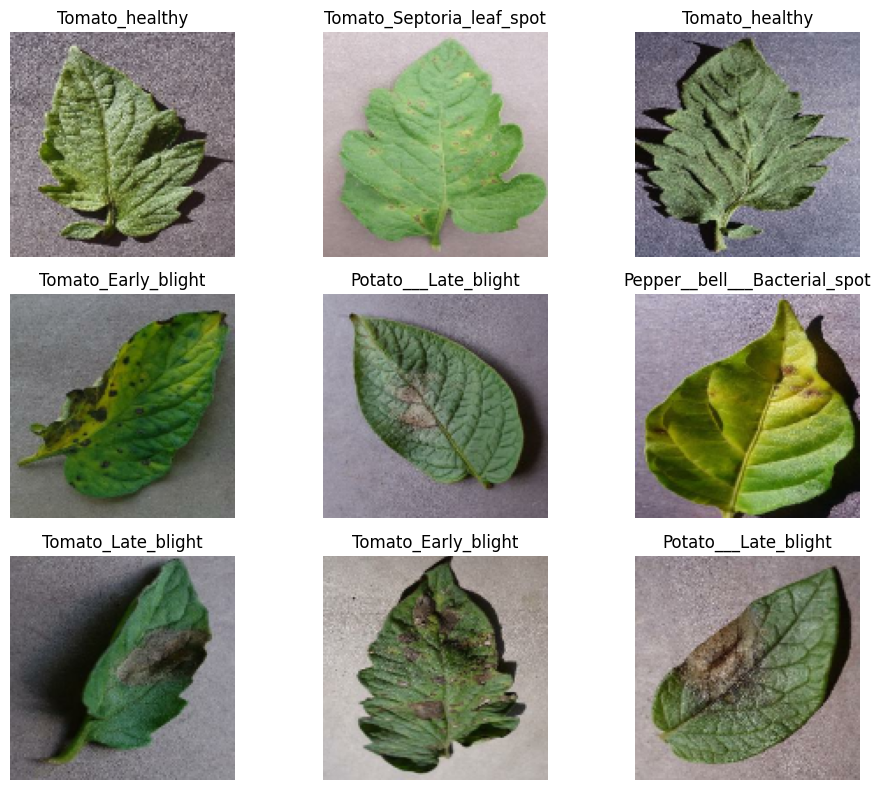

In [ ]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Normalize pixel values from 0–255 to 0–1

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

val_ds = val_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

print("Image preprocessing completed!")
print("Pixel values are now between 0 and 1.")

Image preprocessing completed!
Pixel values are now between 0 and 1.


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Step 9 completed successfully!")

Step 9 completed successfully!


In [ ]:
from tensorflow.keras import layers, models

num_classes = len(class_names)

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,575 (12.61 MB)

 Trainable params: 3,306,575 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

print("Model training completed!")

Epoch 1/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 557s 1s/step - accuracy: 0.5627 - loss: 1.3592 - val_accuracy: 0.7761 - val_loss: 0.6504
Epoch 2/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 552s 1s/step - accuracy: 0.7782 - loss: 0.6559 - val_accuracy: 0.8331 - val_loss: 0.4941
Epoch 3/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 549s 1s/step - accuracy: 0.8402 - loss: 0.4707 - val_accuracy: 0.8968 - val_loss: 0.3297
Epoch 4/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 562s 1s/step - accuracy: 0.8755 - loss: 0.3679 - val_accuracy: 0.8985 - val_loss: 0.3215
Epoch 5/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 557s 1s/step - accuracy: 0.8937 - loss: 0.3092 - val_accuracy: 0.9079 - val_loss: 0.2933
Model training completed!


In [ ]:
loss, accuracy = model.evaluate(val_ds)

print("Validation Loss:", loss)
print("Validation Accuracy:", round(accuracy * 100, 2), "%")

129/129 ━━━━━━━━━━━━━━━━━━━━ 37s 285ms/step - accuracy: 0.9079 - loss: 0.2933
Validation Loss: 0.2932561933994293
Validation Accuracy: 90.79 %


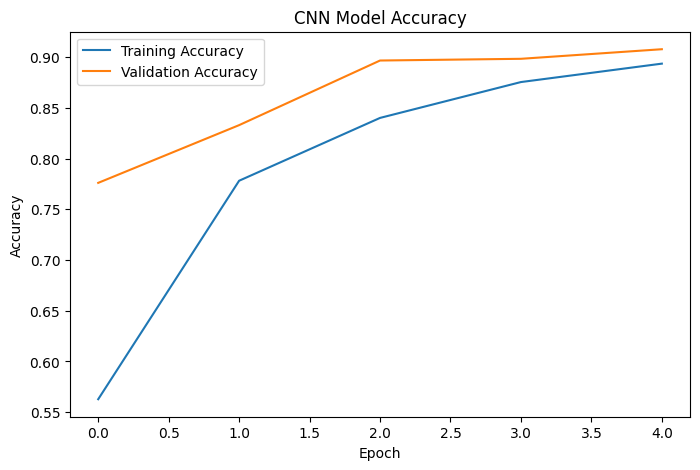

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Model Accuracy")
plt.legend()
plt.show()

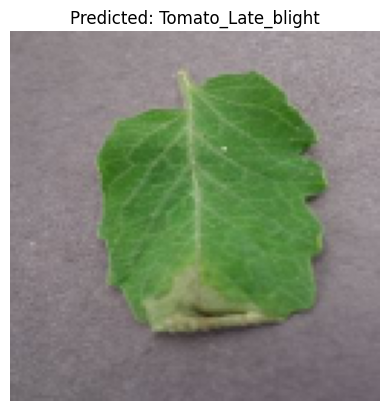

Actual class: Tomato_Late_blight
Predicted class: Tomato_Late_blight
Model confidence: 99.09 %


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

for images, labels in val_ds.take(1):
    image = images[0]
    actual_label = int(labels[0].numpy())

    prediction = model.predict(
        tf.expand_dims(image, axis=0),
        verbose=0
    )

    predicted_label = int(np.argmax(prediction[0]))
    confidence = float(np.max(prediction[0])) * 100

    plt.imshow(image.numpy())
    plt.axis("off")
    plt.title(
        f"Predicted: {class_names[predicted_label]}"
    )
    plt.show()

    print("Actual class:", class_names[actual_label])
    print("Predicted class:", class_names[predicted_label])
    print("Model confidence:", round(confidence, 2), "%")

In [ ]:
model.save("plant_disease_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("plant_disease_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>